In [70]:
import zipfile
z=zipfile.ZipFile("archive.zip")
z.extractall()

In [5]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [6]:
# gestion des fichiers et dossiers 
import os
import shutil
import zipfile

# fonctions aléatoires
import random

# manipulation des données
import numpy as np
import pandas as pd

# traitement des images
import cv2
import skimage
from skimage import segmentation

# visualisation des données
import matplotlib.pyplot as plt
import seaborn as sns

# affichage des graphiques dans Jupyter Notebook
%matplotlib inline

In [7]:
import matplotlib.pyplot as plt

print("Matplotlib fonctionne !")

Matplotlib fonctionne !


In [8]:
labels = ["PNEUMONIA","NORMAL"]
img_size=128
def get_data(data_dir):
    data=[]
    for label in labels :
        #train/pneumonia
        path =os.path.join(data_dir, label)
        class_num = labels.index(label)
        for img in os.listdir(path):
            try:
                img_arr=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
                resized_arr=cv2.resize(img_arr,(img_size,img_size))
                data.append([resized_arr,class_num])
            except Exception as e :
                print(e)
    return data
                

In [9]:
train = get_data("chest_xray/chest_xray/train")
test = get_data("chest_xray/chest_xray/test")
val = get_data("chest_xray/chest_xray/val")

print("Train :", len(train))
print("Test :", len(test))
print("Validation :", len(val))

Train : 5216
Test : 624
Validation : 16


In [10]:
pneumonia=os.listdir("chest_xray/chest_xray/train/PNEUMONIA")
pneumonia_dir = "chest_xray/chest_xray/train/PNEUMONIA"

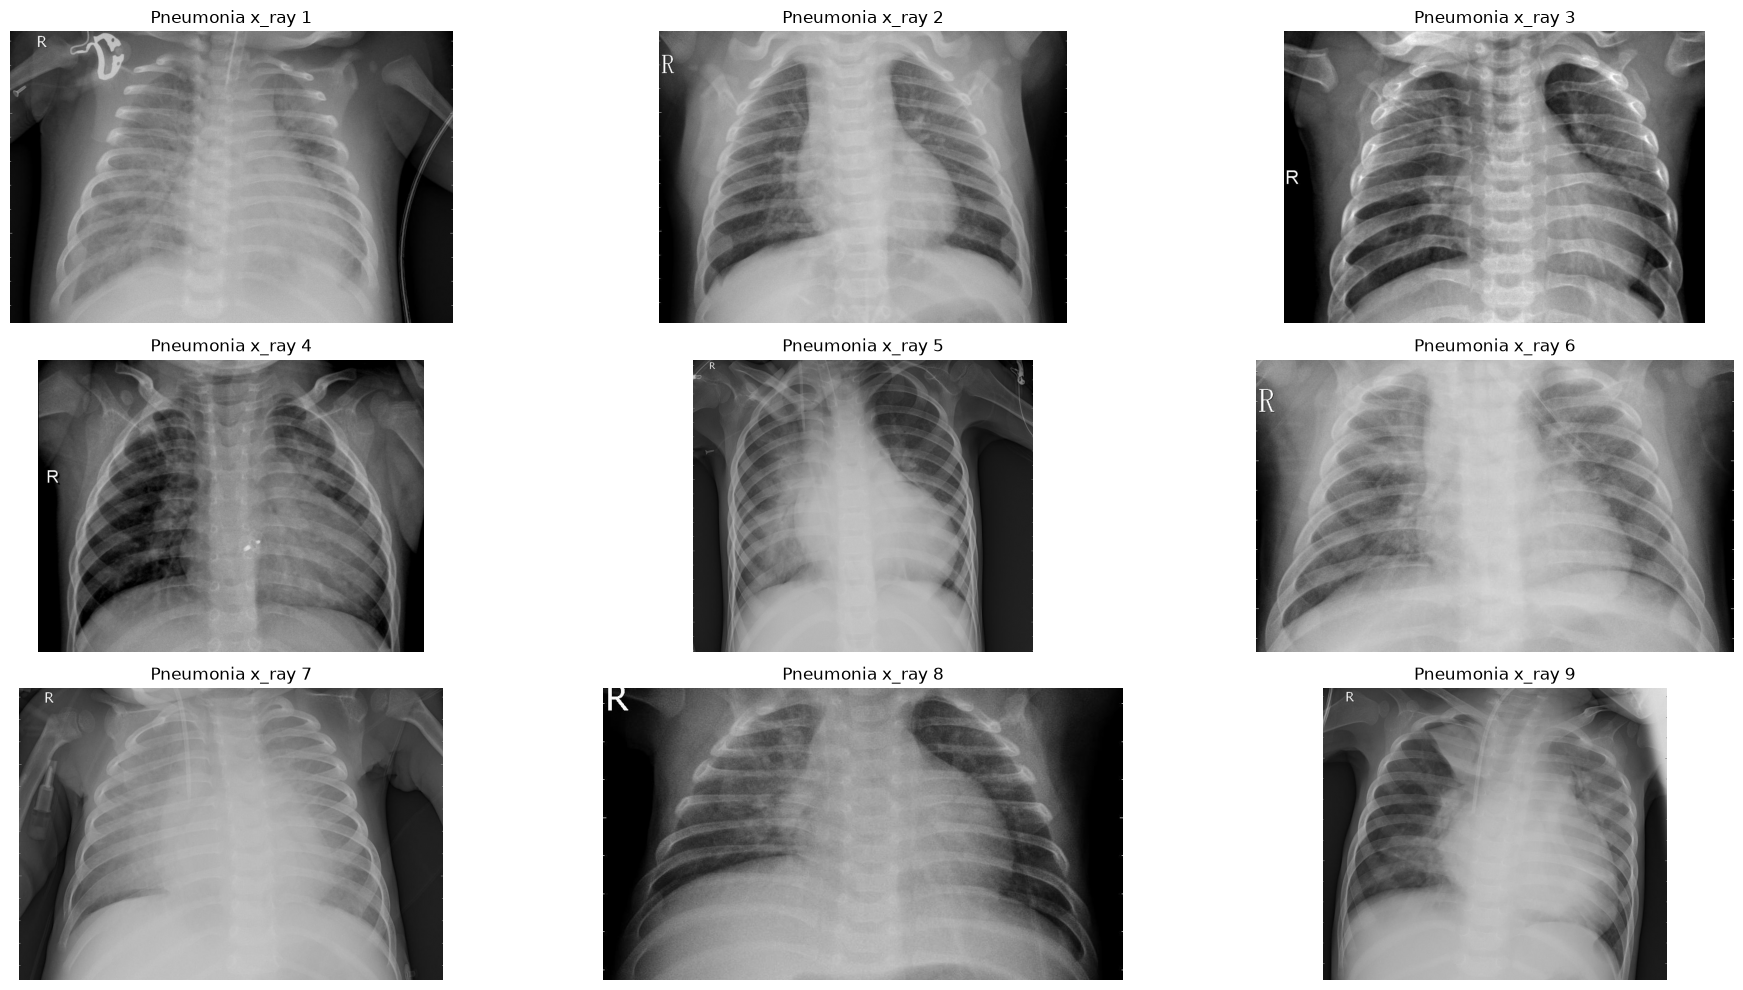

In [11]:
plt.figure(figsize=(20,10))
for i in range (9):
    plt.subplot(3,3,i+1)
    img=plt.imread(os.path.join(pneumonia_dir, pneumonia[i]))
    plt.imshow(img, cmap='gray')
    plt.axis("off")
    plt.title(f"Pneumonia x_ray {i+1}")
plt.tight_layout()   

In [12]:
normal = os.listdir("chest_xray/chest_xray/train/NORMAL")
normal_dir = "chest_xray/chest_xray/train/NORMAL"

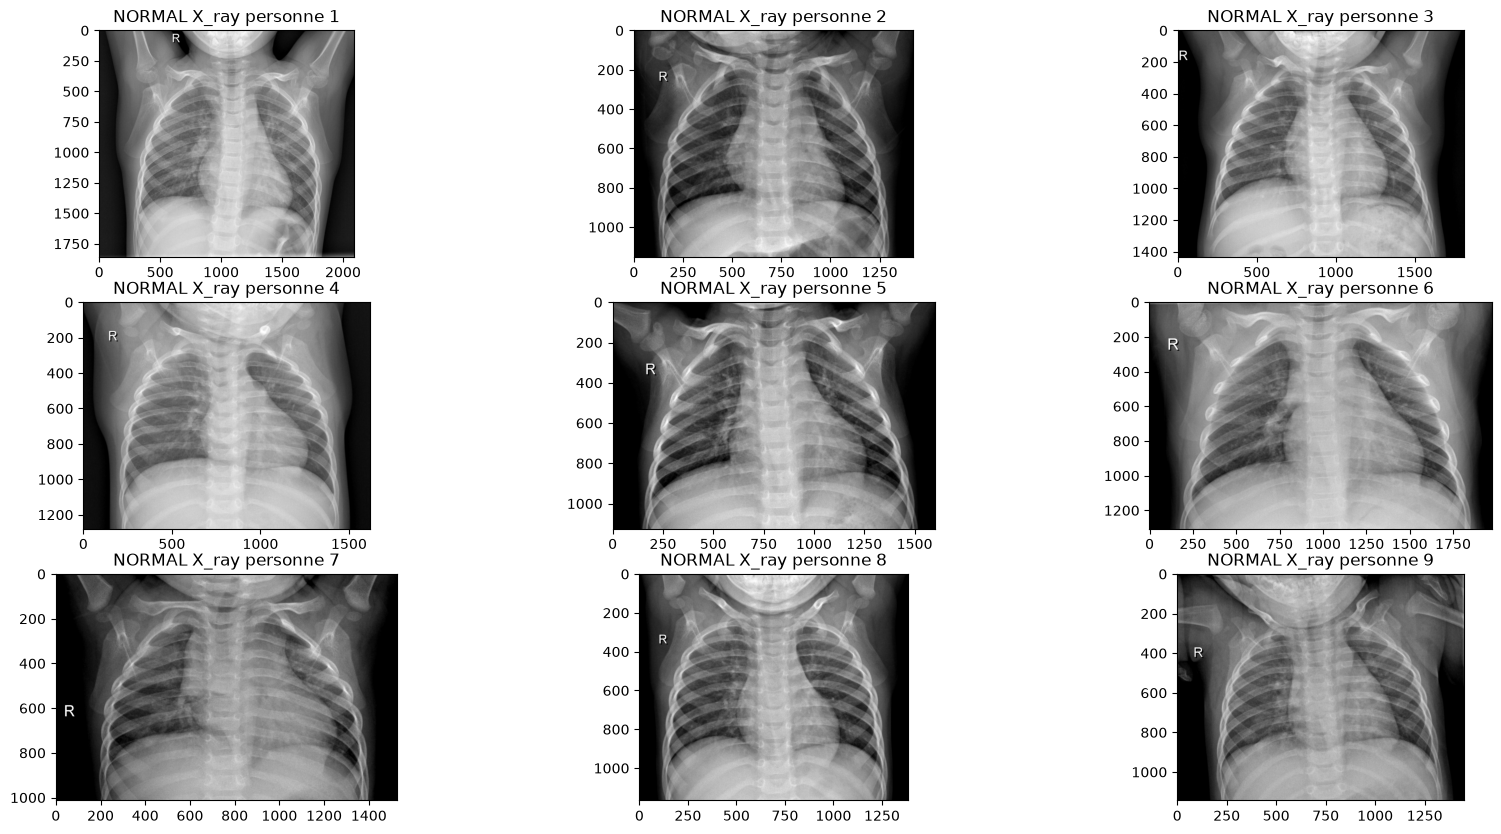

In [13]:
plt.figure(figsize=(20,10))
for i in range (9):
    plt.subplot(3,3,i+1)
    img = plt.imread(os.path.join(normal_dir,normal[i]))
    plt.title(f"NORMAL X_ray personne {i+1}") 
    plt.imshow(img,cmap="gray")
plt.show()
                     


Nombre d'images dans train : 5216
Nombre d'éléments dans listx : 5216


<BarContainer object of 2 artists>

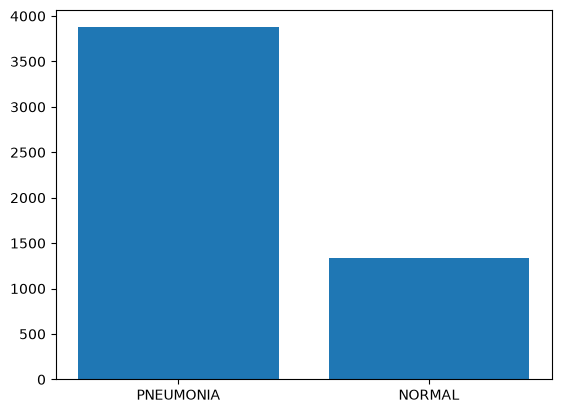

In [14]:
listx=[]
for i in train :
    if (i[1]==0):
        listx.append("PNEUMONIA")
    else: 
        listx.append("NORMAL")
        
print("Nombre d'images dans train :", len(train))
print("Nombre d'éléments dans listx :", len(listx))

plt.bar(["PNEUMONIA","NORMAL"],[listx.count("PNEUMONIA"),listx.count("NORMAL")])

        

In [15]:
# Bibliothèque principale de Deep Learning
import tensorflow as tf

# Data Augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Création et chargement des modèles
from tensorflow.keras.models import Model, load_model

# Couches du réseau de neurones
from tensorflow.keras.layers import (
    Input,
    Dense,
    Flatten,
    MaxPooling2D,
    Conv2D,
    Dropout
)

# Modèle CNN pré-entraîné
from tensorflow.keras.applications.vgg19 import VGG19

# Algorithmes d'optimisation
from tensorflow.keras.optimizers import SGD, RMSprop, Adam

# Fonctions de contrôle de l'entraînement
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)


In [17]:
train_datagen= ImageDataGenerator( rescale =1. / 255,
                  horizontal_flip=0.4,
                   vertical_flip=0.4,
                   rotation_range=40,
                   shear_range=40,
                   width_shift_range=0.4,
                   height_shift_range=0.4,
                   fill_mode="nearest")
valid_datagen= ImageDataGenerator(rescale = 1. / 255)
test_datagen= ImageDataGenerator(rescale=1./ 255)



In [43]:
train_generator= train_datagen.flow_from_directory("chest_xray/chest_xray/train",
                                 batch_size=32,
                                 target_size=(128,128),
                                 class_mode='categorical',
                                  shuffle=True,
                                  seed=42,
                                  color_mode='rgb'
                                 )

valid_generator= valid_datagen.flow_from_directory("chest_xray/chest_xray/val",
                                 batch_size=32,
                                 target_size=(128,128),
                                 class_mode='categorical',
                                  shuffle=True,
                                  seed=42,
                                  color_mode='rgb'
                                 )

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [20]:
class_labels= train_generator.class_indices
class_labels

{'NORMAL': 0, 'PNEUMONIA': 1}

In [44]:
base_model=VGG19(input_shape=(128,128,3),
     include_top=False,
     weights='imagenet')
for layer in base_model.layers:
    layer.trainable=False
x = base_model.output
flat=Flatten()(x)

class_1=Dense(4608,activation='relu')(flat)
dropout= Dropout(0.2)(class_1)
class_2=Dense(4608,activation='relu')(dropout)
output=Dense(2,activation='softmax')(class_2)
model_01 = Model(base_model.inputs,output)
model_01.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4608)           │    37,753,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4608)           │             

 Total params: 79,025,218 (301.46 MB)

 Trainable params: 59,000,834 (225.07 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [45]:
filepath="model.h5"
es=EarlyStopping(monitor="val_loss",verbose=1,mode="min",patience=4)
cp=ModelCheckpoint(filepath,monitor="val_loss",save_best_only=True,save_weights_only=False,mode="auto",save_freq="epoch")
lrr=ReduceLROnPlateau(monitor="val_accuracy",patience=3,verbose=1,factor=0.5,min_lr=0.0001)

sgd=SGD(learning_rate=0.0001,momentum=0.9,nesterov=True)
model_01.compile(loss="categorical_crossentropy",optimizer=sgd,metrics=['accuracy'])

In [46]:
model_01.fit(train_generator,
             steps_per_epoch=50,
             epochs=1,
             callbacks=[es,cp,lrr],
             validation_data=val_generator)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7437 - loss: 0.5443

50/50 ━━━━━━━━━━━━━━━━━━━━ 150s 3s/step - accuracy: 0.7437 - loss: 0.5443 - val_accuracy: 0.5000 - val_loss: 0.7860 - learning_rate: 1.0000e-04


In [47]:
if not os.path.isdir('model_weights/'):
    os.mkdir('model_weights/')
model_01.save(filepath="model_weights/vgg19_model_1.keras",overwrite=True)


In [48]:
from tensorflow.keras.models import load_model

model = load_model(
    "model_weights/vgg19_model_1.keras",
    compile=False
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4608)           │    37,753,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4608)           │             

 Total params: 79,025,218 (301.46 MB)

 Trainable params: 59,000,834 (225.07 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [56]:
test_generator= test_datagen.flow_from_directory("chest_xray/chest_xray/test",
                                 batch_size=32,
                                 target_size=(128,128),
                                 class_mode='categorical',
                                  shuffle=False,
                                  seed=42,
                                  color_mode='rgb'
                                 )

Found 624 images belonging to 2 classes.


In [58]:
model_01 = load_model("model_weights/vgg19_model_1.keras")

vgg_val_eval_01 = model_01.evaluate(val_generator)

vgg_test_eval_01 = model_01.evaluate(test_generator)

print("Validation Accuracy :", vgg_val_eval_01[1])
print("Test Accuracy :", vgg_test_eval_01[1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.7860
20/20 ━━━━━━━━━━━━━━━━━━━━ 63s 3s/step - accuracy: 0.6250 - loss: 0.6258
Validation Accuracy : 0.5
Test Accuracy : 0.625


In [ ]:
#incermetal unfreezing and fine tuning 

In [59]:
# Récupérer les couches de VGG19
for layer in model_01.layers:

    # Débloquer uniquement les convolutions du dernier bloc
    if layer.name.startswith("block5_conv"):
        layer.trainable = True

    # Garder les autres couches de VGG19 gelées
    elif layer.name.startswith("block"):
        layer.trainable = False

# Vérifier les couches entraînables
for layer in model_01.layers:
    print(layer.name, layer.trainable)

input_layer_4 True
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_conv4 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_conv4 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_conv4 True
block5_pool False
flatten_3 True
dense_7 True
dropout_3 True
dense_8 True
dense_9 True


In [60]:
model_01.compile(
    optimizer=Adam(learning_rate=0.000001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [61]:
history_fine = model_01.fit(
    train_generator,
    epochs=5,
    validation_data=val_generator
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 639s 4s/step - accuracy: 0.7847 - loss: 0.4453 - val_accuracy: 0.7500 - val_loss: 0.5592
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 585s 4s/step - accuracy: 0.8390 - loss: 0.3492 - val_accuracy: 0.7500 - val_loss: 0.5954
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 537s 3s/step - accuracy: 0.8616 - loss: 0.3106 - val_accuracy: 0.7500 - val_loss: 0.6968
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 533s 3s/step - accuracy: 0.8754 - loss: 0.2844 - val_accuracy: 0.6250 - val_loss: 0.8320
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 511s 3s/step - accuracy: 0.8836 - loss: 0.2715 - val_accuracy: 0.6875 - val_loss: 0.8512


In [62]:
model_01.save("model_weights/vgg19_finetuned.keras")

print("Modèle sauvegardé !")

Modèle sauvegardé !


In [63]:
fine_val_eval = model_01.evaluate(val_generator)

fine_test_eval = model_01.evaluate(test_generator)

print("Avant Fine-Tuning :", vgg_test_eval_01[1])
print("Après Fine-Tuning :", fine_test_eval[1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6875 - loss: 0.8512
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.8253 - loss: 0.4186
Avant Fine-Tuning : 0.625
Après Fine-Tuning : 0.8253205418586731
